# Pareto (prioritisation) analysis

**Question:** which clinical measures, and which hospitals, account for most of the readmission
burden that HRRP penalises?

**Is actual cost data available? No.** None of the source files contain hospital-level readmission
costs or dollar penalty amounts. The Supplemental File's *DRG payment ratio* is a weight (a measure's
share of a hospital's base DRG payments), not money. So this notebook uses three clearly labelled
**substitute metrics** and never converts anything to dollars:

| Metric | Definition | Source | What it is *not* |
|---|---|---|---|
| **A. Payment-reduction contribution** (percentage points) | Each measure's share of a hospital's official payment reduction, rebuilt with the CMS formula: `NM × DRG ratio × (ERR − peer median ERR)` for measures with penalty indicator = Y, scaled to the 3% cap | Supplemental File | Not dollars. Points are summed across hospitals of different sizes. |
| **B. Estimated excess readmissions** | `readmissions × (1 − 1/ERR)` for hospitals with ERR > 1 | HRRP file (derived) | Not a CMS-published count. Uses only rows where CMS reported the readmission count. |
| **C. Penalty flags** | Number of hospitals with penalty indicator = Y | Supplemental File | Close to 50% of eligible hospitals by design (peer median threshold) |

Pareto analysis ranks categories by contribution to a total. It **prioritises**. It does not show
that a measure *causes* costs.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import statistical_analysis as sa, visualizations as viz

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
viz.set_style()
PROC, TABLES = ROOT / "data" / "processed", ROOT / "reports" / "tables"
SHORT = {"AMI": "AMI", "CABG": "CABG", "COPD": "COPD", "HF": "Heart failure", "HIP_KNEE": "Hip/knee", "PN": "Pneumonia"}
mf  = pd.read_csv(PROC / "measure_fact.csv", dtype={"FACILITY_ID": str})
dim = pd.read_csv(PROC / "hospital_dim.csv", dtype={"FACILITY_ID": str})
supp = dim[dim["IN_SUPPLEMENTAL"]].copy()

def labelled(t):
    t = t.copy(); t.iloc[:, 0] = t.iloc[:, 0].map(SHORT); return t

## A. Contribution to the official HRRP payment reduction

First, check that the CMS formula reproduces the published reduction for every hospital. If it
didn't, the per-measure attribution could not be trusted.

In [2]:
contrib = sa.payment_contributions(mf, dim)
diff = sa.reconstruction_check(contrib)
print(f"hospitals: {diff.size:,} | max |reconstructed - official| = {diff.max():.4f} pp | "
      f"within 0.01 pp: {(diff <= 0.01).mean():.1%}")

hospitals: 2,937 | max |reconstructed - official| = 0.0063 pp | within 0.01 pp: 100.0%


In [3]:
# Why do more hospitals have a positive contribution than have a factor below 1.0000?
h = contrib.groupby("FACILITY_ID").agg(recon=("CONTRIB_PCT_POINTS", "sum"), official=("PAYMENT_REDUCTION_PCT", "first"))
gap = h[(h.recon > 0) & (h.official == 0)]
print(f"positive contribution: {(h.recon > 0).sum():,} | official reduction > 0: {(h.official > 0).sum():,} | "
      f"positive but published as 0.00%: {len(gap)} (max reconstructed {gap.recon.max():.4f} pp)")

positive contribution: 2,336 | official reduction > 0: 2,302 | positive but published as 0.00%: 34 (max reconstructed 0.0051 pp)


The gap comes from hospitals whose reconstructed reduction is a few thousandths of a percentage point.
CMS publishes the factor to 4 decimal places, so these round to a factor of 1.0000 (0.00%). They add
almost nothing to the totals below.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


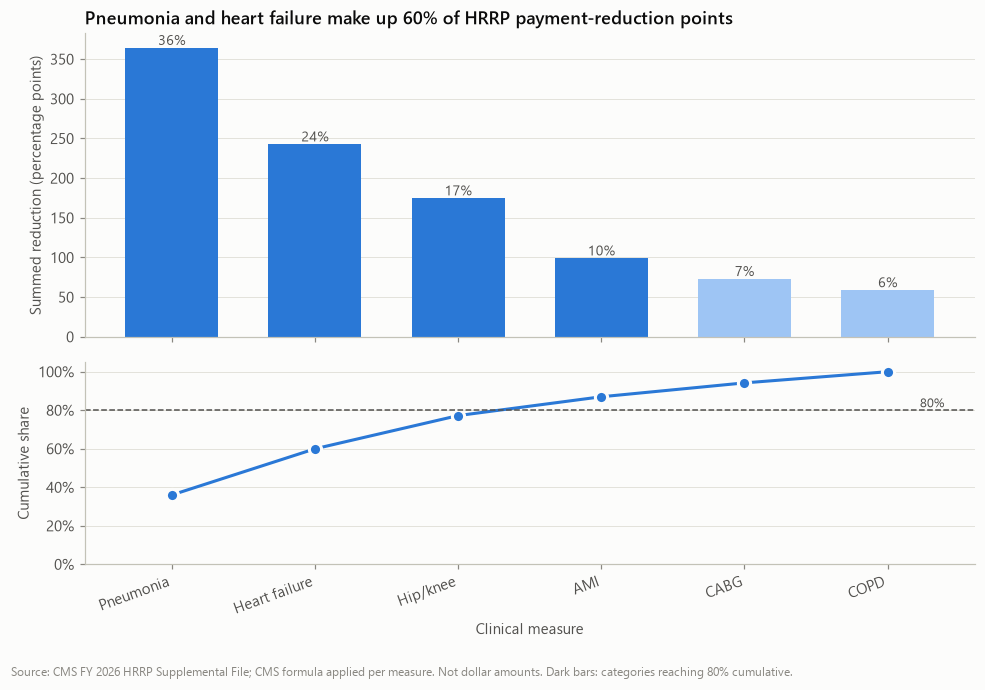

,MEASURE_CODE,VALUE,SHARE_PCT,CUMULATIVE_PCT,VITAL_FEW
0,PN,364.18,35.99,35.99,True
1,HF,242.63,23.97,59.96,True
2,HIP_KNEE,174.60,17.25,77.21,True
3,AMI,98.88,9.77,86.98,True
4,CABG,72.94,7.21,94.19,False
5,COPD,58.78,5.81,100.00,False


In [4]:
pa = sa.pareto_table(contrib, "MEASURE_CODE", "CONTRIB_PCT_POINTS")
pa.to_csv(TABLES / "pareto_payment_contribution.csv", index=False)
viz.pareto_chart(labelled(pa), "Clinical measure", "Summed reduction (percentage points)",
                 "Pneumonia and heart failure make up 60% of HRRP payment-reduction points",
                 name="10_pareto_payment_contribution",
                 note="Source: CMS FY 2026 HRRP Supplemental File; CMS formula applied per measure. Not dollar amounts")
plt.show(); pa

In [5]:
# Sensitivity: do hospitals at the 3% cap distort the ranking?
capped = supp.loc[supp.PAYMENT_REDUCTION_PCT >= 3, "FACILITY_ID"]
pa_nocap = sa.pareto_table(contrib[~contrib.FACILITY_ID.isin(capped)], "MEASURE_CODE", "CONTRIB_PCT_POINTS")
print(f"{len(capped)} capped hospitals excluded"); pa_nocap[["MEASURE_CODE", "SHARE_PCT", "CUMULATIVE_PCT"]]

15 capped hospitals excluded


,MEASURE_CODE,SHARE_PCT,CUMULATIVE_PCT
0,PN,37.18,37.18
1,HF,24.84,62.02
2,HIP_KNEE,14.23,76.25
3,AMI,10.20,86.45
4,CABG,7.52,93.97
5,COPD,6.03,100.00


**Interpretation.** Pneumonia (36%) and heart failure (24%) together make up 60% of all payment-reduction
points. Adding hip/knee (17%) and AMI (10%) brings the total to 87%. Four of six measures are needed to
pass 80%, so this is **not a sharp 80/20 split**. It is a clear **ranking**: the two high-volume medical
conditions come first. Dropping the 15 hospitals at the 3% cap leaves the order unchanged.

Why these measures lead: a measure's contribution combines **how far** a hospital exceeds its peer median
with **how much of its Medicare payment** the condition represents (the DRG ratio). Pneumonia and heart
failure are common, high-payment admissions. Hip/knee ranks third despite fewer flags because its ERRs
spread widely (notebook 01, §2). Flagged hip/knee hospitals exceed their peer median by 0.130 on average,
against 0.04–0.08 for the other measures, which outweighs its low payment weight (median DRG ratio 0.009 vs 0.047 for pneumonia).

## B. Estimated excess readmissions

rows with an estimate: 11,523 of 18,330 | hospitals with ERR > 1 in those rows: 5,565
sum of positive excess: 12,413 | net across ALL hospitals (above + below 1): 403


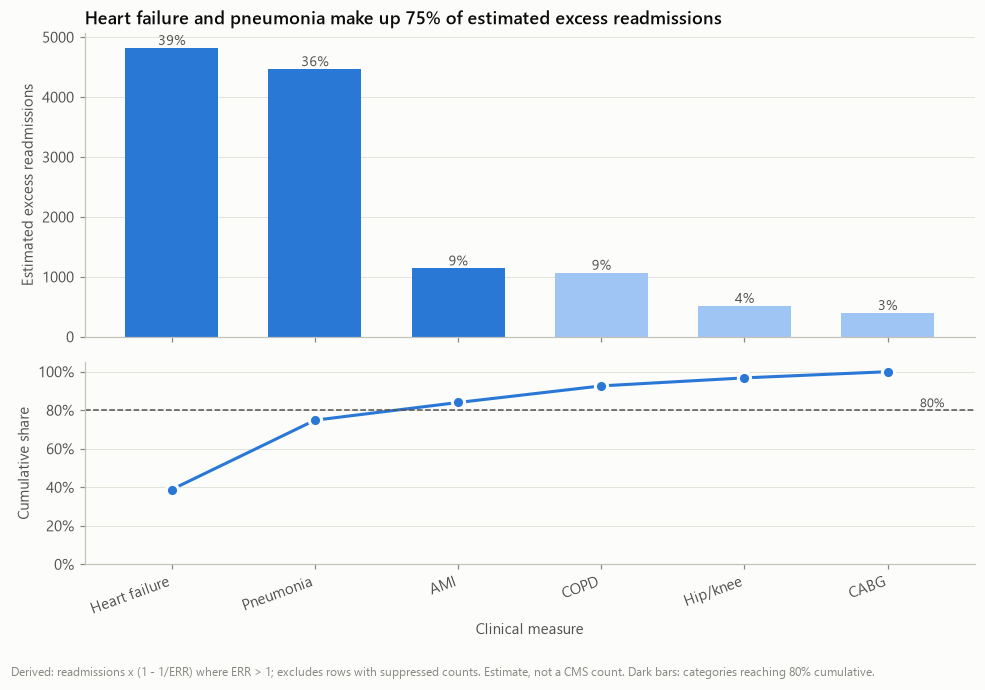

,MEASURE_CODE,VALUE,SHARE_PCT,CUMULATIVE_PCT,VITAL_FEW
0,HF,"4,820.40",38.83,38.83,True
1,PN,"4,466.71",35.98,74.82,True
2,AMI,"1,141.56",9.20,84.01,True
3,COPD,"1,070.06",8.62,92.63,False
4,HIP_KNEE,516.23,4.16,96.79,False
5,CABG,398.18,3.21,100.00,False


In [6]:
est = mf[mf.EST_EXCESS_READMISSIONS.notna()].copy()
pos = est.assign(EXCESS_POS=est.EST_EXCESS_READMISSIONS.clip(lower=0))
pb = sa.pareto_table(pos, "MEASURE_CODE", "EXCESS_POS")
pb.to_csv(TABLES / "pareto_est_excess_readmissions.csv", index=False)
print(f"rows with an estimate: {len(est):,} of {len(mf):,} | hospitals with ERR > 1 in those rows: "
      f"{(est.EST_EXCESS_READMISSIONS > 0).sum():,}")
print(f"sum of positive excess: {pb.VALUE.sum():,.0f} | net across ALL hospitals (above + below 1): "
      f"{est.EST_EXCESS_READMISSIONS.sum():,.0f}")
viz.pareto_chart(labelled(pb), "Clinical measure", "Estimated excess readmissions",
                 "Heart failure and pneumonia make up 75% of estimated excess readmissions",
                 name="11_pareto_est_excess_readmissions",
                 note="Derived: readmissions x (1 - 1/ERR) where ERR > 1; excludes rows with suppressed counts. Estimate, not a CMS count")
plt.show(); pb

**Interpretation.** At hospitals that perform worse than expected, heart failure (39%) and pneumonia (36%)
make up about three-quarters of the estimated readmissions above expected. AMI brings the total to 84%.
This volume-based view agrees with the payment view (A) on the top two conditions.

**Caveats:**
* The **net** total across all hospitals is close to zero (about 400) because ERR is centred on 1 by
  construction. Hospitals below 1 "offset" those above. The positive-only sum (≈12,400) describes room for
  improvement at above-expected hospitals. It is not a national excess.
* About 37% of hospital-measure rows have no estimate because the readmission count was suppressed or missing.
  These rows come from smaller hospitals (median 70 beds vs 192 for rows with an estimate). So B under-represents small hospitals.
* `1 − 1/ERR` treats a hospital's ERR as if it applied directly to its observed readmissions. CMS's ERR
  comes from a hierarchical model, so this is an approximation for ranking only.

## C. Penalty flags by measure

In [7]:
pc = sa.pareto_table(mf.assign(FLAG=mf.PENALTY_INDICATOR.eq("Y").astype(int)), "MEASURE_CODE", "FLAG")
pc.to_csv(TABLES / "pareto_penalty_flags.csv", index=False); pc

,MEASURE_CODE,VALUE,SHARE_PCT,CUMULATIVE_PCT,VITAL_FEW
0,PN,1321,22.86,22.86,True
1,HF,1291,22.34,45.20,True
2,COPD,1142,19.76,64.96,True
3,AMI,882,15.26,80.22,True
4,HIP_KNEE,705,12.20,92.42,False
5,CABG,438,7.58,100.00,False


**Interpretation.** Flag counts mostly follow **how many hospitals are eligible** for each measure, because
about half of eligible hospitals are flagged by design. Pneumonia, heart failure and COPD lead because
almost every hospital treats them. Flags are a poor guide to priority on their own. COPD has the
third-most flags but contributes the *least* to payment reductions (A). Its flagged hospitals exceed the peer median by the
smallest margin (mean 0.040), and COPD is a small share of payments (median DRG ratio 0.011).

## D. Concentration across hospitals

986 of 2,937 hospitals (33.6%) account for 80% of summed reduction points


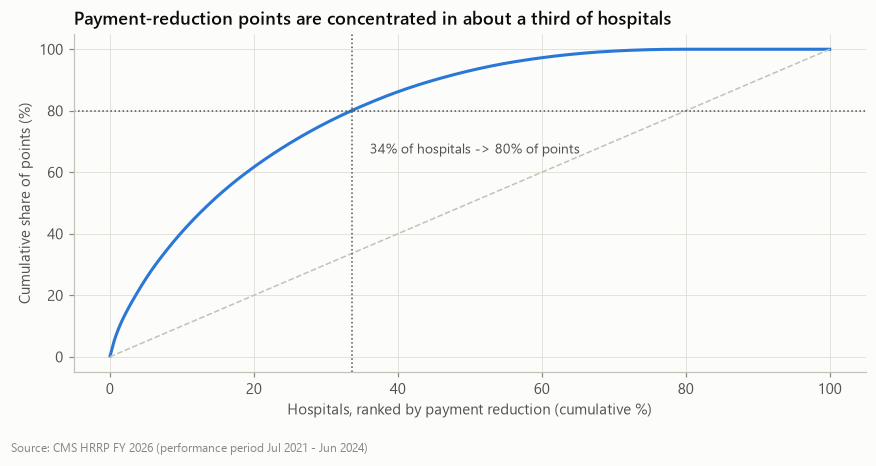

In [8]:
hosp = contrib.groupby("FACILITY_ID")["CONTRIB_PCT_POINTS"].sum().sort_values(ascending=False)
share = hosp.cumsum() / hosp.sum()
k80 = int((share < 0.80).sum() + 1)
print(f"{k80:,} of {hosp.size:,} hospitals ({k80 / hosp.size:.1%}) account for 80% of summed reduction points")

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(1, hosp.size + 1) / hosp.size * 100
ax.plot(x, share.values * 100, color=viz.CATEGORICAL[0], lw=2)
ax.plot([0, 100], [0, 100], color=viz.AXIS, lw=1, ls="--")
ax.axhline(80, color=viz.INK_2, lw=1, ls=":"); ax.axvline(k80 / hosp.size * 100, color=viz.INK_2, lw=1, ls=":")
ax.annotate(f"{k80 / hosp.size:.0%} of hospitals -> 80% of points", (k80 / hosp.size * 100, 80),
            xytext=(12, -28), textcoords="offset points", fontsize=9, color=viz.INK_2)
ax.set_xlabel("Hospitals, ranked by payment reduction (cumulative %)"); ax.set_ylabel("Cumulative share of points (%)")
ax.set_title("Payment-reduction points are concentrated in about a third of hospitals")
fig.tight_layout(); viz._finish(fig, "12_hospital_concentration_curve"); plt.show()

In [9]:
nflag = mf[mf.PENALTY_INDICATOR.eq("Y")].groupby("FACILITY_ID").size()
s = supp.set_index("FACILITY_ID").assign(MEASURES_FLAGGED=nflag).fillna({"MEASURES_FLAGGED": 0})
prof = s.groupby("MEASURES_FLAGGED").agg(hospitals=("STATE", "size"), mean_reduction_pct=("PAYMENT_REDUCTION_PCT", "mean"))
prof["share_of_hospitals"] = prof.hospitals / prof.hospitals.sum()
# Share of points held by hospitals flagged on 3+ measures (quoted in the interpretation below)
hosp_flags = nflag.reindex(hosp.index).fillna(0)
print(f"hospitals flagged on 3+ measures: {(s.MEASURES_FLAGGED >= 3).mean():.1%} of hospitals, "
      f"{hosp[hosp_flags >= 3].sum() / hosp.sum():.1%} of points")
prof.to_csv(TABLES / "hospitals_by_measures_flagged.csv"); prof

hospitals flagged on 3+ measures: 35.4% of hospitals, 66.9% of points


,hospitals,mean_reduction_pct,share_of_hospitals
MEASURES_FLAGGED,,,
0.00,599,0.00,0.20
1.00,654,0.21,0.22
2.00,645,0.31,0.22
3.00,526,0.53,0.18
4.00,333,0.67,0.11
5.00,155,0.96,0.05
6.00,25,1.11,0.01


In [10]:
# Do flags cluster? Among hospitals eligible for both HF and PN, compare P(PN flag | HF flag) with P(PN flag | no HF flag).
w = mf[mf.ELIGIBLE_DISCHARGES >= 25].pivot_table(index="FACILITY_ID", columns="MEASURE_CODE",
                                                  values="PENALTY_INDICATOR", aggfunc="first")
both = w[["HF", "PN"]].dropna()
ct = pd.crosstab(both.HF, both.PN)
cond = (ct["Y"] / ct.sum(axis=1)).rename("P(PN flagged)")
chi = sa.chi_square(both.rename(columns={"HF": "HF_FLAG", "PN": "PN_FLAG"}), "HF_FLAG", "PN_FLAG")
print(f"n = {len(both):,} hospitals eligible for both | chi2 p = {chi['p']:.2e} | Cramer's V = {chi['cramers_v']:.2f}")
cond.to_frame()

n = 2,553 hospitals eligible for both | chi2 p = 9.45e-25 | Cramer's V = 0.20


,P(PN flagged)
HF,
N,0.40
Y,0.60


**Interpretation.**
* About **a third of hospitals account for 80% of payment-reduction points**. Hospital-level concentration
  is stronger than measure-level concentration, so *which hospitals* matters more than *which condition*
  for targeting.
* The mean reduction rises steeply with the number of flagged measures. Hospitals flagged on 3+ measures
  (35% of hospitals) account for 67% of all payment-reduction points.
* Heart failure and pneumonia flags **cluster**: a hospital flagged on HF is more likely to also be flagged
  on pneumonia. Together with the positive cross-measure ERR correlations (notebook 01, §6), this is
  *consistent with* hospital-wide factors (such as discharge and follow-up processes) as well as
  condition-specific ones. These data cannot show which factors are at work.

## Conclusions for prioritisation
1. **Heart failure and pneumonia** rank first on both payment contribution (60%) and estimated excess
   volume (75%). They are the clearest first targets for care-transition work.
2. **Hip/knee replacement** is third for payment contribution despite fewer flags. That points to a smaller
   set of hospitals with large excess ratios, so investigate it hospital by hospital, not system-wide.
3. **COPD** has many flags but small contributions. Treat it as lower priority unless a hospital's own data says otherwise.
4. **Target hospitals flagged on several measures.** About a third of hospitals make up 80% of points.
   Hospital rankings within states are in `reports/sql_results/hospital_rankings__*.csv`.

None of this estimates dollars saved. Converting points to money needs each hospital's base operating DRG
payments, which these files do not provide.